# Notebook 06: Figures for the paper

Makes the two figures used in the research paper **only from the saved result files**
in `experiments/` (made by notebook 05). Nothing is trained here, so it runs in a few
seconds.

- **Figure 1:** recall of each class as the maximum depth shrinks, for list A and list
  A-NS (A without the shortcut features). Mean of the 5 splits. Source:
  `S6_summary_by_depth.csv`.
- **Figure 2:** macro F1 (without Heartbleed) against compact model size, for the two
  ways of shrinking a tree: depth limits and cost-complexity pruning, lists A and C,
  split 42 (the pruning sweep was only run on split 42). Sources: `S6_depth_sweep.csv`,
  `S6_ccp_sweep.csv`.

Colours follow a colour-blind-checked palette, and every line also has its own marker
and line style, so the figures still work in black-and-white print.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

try:  # In Colab, read the files notebook 05 wrote to Drive
    from google.colab import drive
    drive.mount("/content/drive")
    REPO_DIR = Path("/content/drive/MyDrive/Colab Notebooks/threat detector")
except ImportError:  # Locally, read the repo's experiments/ folder
    REPO_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXP = REPO_DIR / "experiments"
FIG_DIR = EXP / "figures"
FIG_DIR.mkdir(exist_ok=True)

summary = pd.read_csv(EXP / "S6_summary_by_depth.csv", dtype={"max_depth": str})
depth = pd.read_csv(EXP / "S6_depth_sweep.csv", dtype={"max_depth": str})
ccp = pd.read_csv(EXP / "S6_ccp_sweep.csv")

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
MARKERS = ["o", "s", "^", "D", "v"]
STYLES = ["-", "--", "-.", ":", (0, (5, 1))]
plt.rcParams.update({"font.family": "serif", "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
DEPTH_ORDER = ["1", "2", "3", "4", "5", "6", "8", "10", "12", "15", "20", "none"]
CLASSES = ["BENIGN", "DoS Hulk", "DoS GoldenEye", "DoS slowloris", "DoS Slowhttptest"]

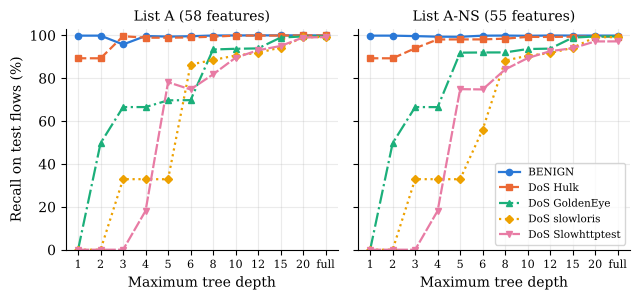

In [2]:
# Figure 1: recall of each class vs maximum depth (lists A and A-NS, mean of 5 splits)
fig, axes = plt.subplots(1, 2, figsize=(6.5, 3.1), sharey=True)
for ax, set_name, n in zip(axes, ["A", "A-NS"], [58, 55]):
    s = summary[summary["feature_set"] == set_name].set_index("max_depth").loc[DEPTH_ORDER]
    for i, c in enumerate(CLASSES):
        ax.plot(range(len(DEPTH_ORDER)), 100 * s[f"recall_{c.replace(' ', '_')}_mean"],
                color=COLORS[i], marker=MARKERS[i], linestyle=STYLES[i], linewidth=1.6,
                markersize=4.5, label=c)
    ax.set_xticks(range(len(DEPTH_ORDER)))
    ax.set_xticklabels([("full" if d == "none" else d) for d in DEPTH_ORDER], fontsize=8)
    ax.set_xlabel("Maximum tree depth")
    ax.set_title(f"List {set_name} ({n} features)", fontsize=10)
axes[0].set_ylabel("Recall on test flows (%)")
axes[0].set_ylim(0, 103)
axes[1].legend(loc="lower right", fontsize=7.5, frameon=True)
fig.tight_layout()
fig.savefig(FIG_DIR / "paper_fig1_per_class_recall_vs_depth.png", dpi=300)
plt.show()

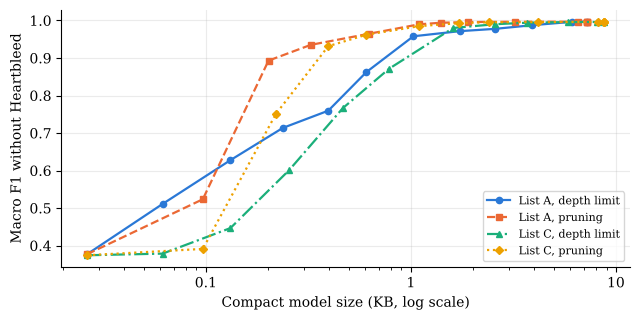

Saved to /home/user/threat-detection-model/experiments/figures


In [3]:
# Figure 2: macro F1 vs compact size, depth limits vs cost-complexity pruning (split 42)
fig, ax = plt.subplots(figsize=(6.5, 3.3))
lines = [
    ("A", "depth", "List A, depth limit"),
    ("A", "ccp", "List A, pruning"),
    ("C", "depth", "List C, depth limit"),
    ("C", "ccp", "List C, pruning"),
]
for i, (set_name, how, label) in enumerate(lines):
    if how == "depth":
        d = depth[(depth["seed"] == 42) & (depth["feature_set"] == set_name)]
    else:
        d = ccp[ccp["feature_set"] == set_name]
    d = d.sort_values("compact_bytes")
    ax.plot(d["compact_bytes"] / 1024, d["macro_f1_no_hb"], color=COLORS[i], marker=MARKERS[i],
            linestyle=STYLES[i], linewidth=1.6, markersize=4.5, label=label)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlabel("Compact model size (KB, log scale)")
ax.set_ylabel("Macro F1 without Heartbleed")
ax.legend(loc="lower right", fontsize=8, frameon=True)
fig.tight_layout()
fig.savefig(FIG_DIR / "paper_fig2_depth_vs_pruning.png", dpi=300)
plt.show()
print("Saved to", FIG_DIR)